---
title: "3.5.d Escenarios: fuego, sequía y punto de no retorno"
short_title: "d. Escenarios"
subtitle: "Proyecciones de condiciones secas y cálidas que favorecen el fuego"
description: "Escenarios CMIP6 para las condiciones meteorológicas de incendio en Leticia y riesgo de transición del bosque."
keywords: [incendios, CMIP6, punto de no retorno, deforestación, Amazonía]
---

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mromerot/leticia/blob/main/book/03_analisis/35_incendios/d_escenarios.ipynb)

In [1]:
# Preparación del entorno. En Colab instala el paquete del proyecto desde GitHub (1–2 minutos);
# en una copia local usa el paquete ya instalado con `pip install -e .`.
import sys, subprocess
if "google.colab" in sys.modules:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "leticia @ git+https://github.com/mromerot/leticia"], check=True)
from leticia.libro import preparar, intentar
preparar()

El riesgo de incendio en el futuro depende de dos fuerzas: el **clima**, que hará las estaciones secas más cálidas
y con mayor déficit hídrico, y el **uso del suelo**, que decide cuánto bosque se abre y cuánta ignición hay.
Flores et al. estiman que hacia 2050 entre el 10 % y el 47 % del bosque amazónico estará expuesto a
perturbaciones combinadas que podrían desencadenar transiciones del ecosistema [@flores2024].

In [2]:
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from matplotlib.patches import Patch

from leticia import aoi, clima, espacial, exposicion, fuentes, riesgo, viz
from leticia.config import parametros

pi = parametros()["incendios"]
urbana = aoi.area_urbana()
mun = fuentes.limite_municipal()


def focos(sensor="modis", anios=None):
    f = fuentes.focos_calor(sensor, anios)
    if sensor == "modis":
        f = f[f["confidence"] >= pi["confianza_modis_min"]]
    else:
        f = f[f["confidence"].astype(str).str.lower().isin(pi["confianza_viirs"])]
    f = f[f["type"] == 0] if "type" in f else f          # solo vegetación (excluye fuentes estáticas y volcanes)
    return gpd.GeoDataFrame(f, geometry=gpd.points_from_xy(f.longitude, f.latitude), crs=4326)

## 1. Condiciones que favorecen el fuego (CCKP)

In [3]:
VARS = {"tasmax": "temperatura máxima (°C)", "cdd": "máx. días secos consecutivos", "spei12": "SPEI-12", "hd35": "días con Tmax > 35 °C"}
tabla = fuentes.cckp_tabla(list(VARS))
med = tabla[tabla.percentil == "median"].pivot_table(index="variable", columns=["periodo", "escenario"], values="valor")
med.columns = [f"{p} {viz.NOMBRE_ESC[e]}" for p, e in med.columns]
med.index = [VARS[v] for v in med.index]
display(Markdown("**Cambio proyectado respecto a 1995–2014 (mediana del ensamble):**"))
display(med.round(2))

**Cambio proyectado respecto a 1995–2014 (mediana del ensamble):**

,2040-2059 SSP1-2.6,2040-2059 SSP2-4.5,2040-2059 SSP5-8.5,2080-2099 SSP1-2.6,2080-2099 SSP2-4.5,2080-2099 SSP5-8.5
máx. días secos consecutivos,0.75,0.70,0.80,0.60,1.05,2.15
días con Tmax > 35 °C,3.15,4.95,19.60,4.20,26.05,152.70
SPEI-12,-0.43,-0.62,-0.93,-0.50,-0.90,-2.00
temperatura máxima (°C),1.04,1.24,1.78,1.09,2.18,4.83


In [4]:
viz.pie(viz.nota_fuente("proyecciones_cckp"))

*Fuente: Banco Mundial – Climate Change Knowledge Portal (CCKP) — CMIP6 0,25° (reducción de escala estadística), SSP1-2.6, SSP2-4.5, SSP5-8.5.*

## 2. Anticipar la temporada: el Atlántico Norte tropical

Chen et al. mostraron que las anomalías de la temperatura superficial del mar (TSM) permiten anticipar la severidad
de la temporada de incendios en Suramérica con tres a cinco meses de anticipación [@chen2011fire]. Para la Amazonía
occidental, Fernandes et al. encontraron que la lluvia de julio–septiembre, y con ella los focos de calor, depende
sobre todo de la TSM del **Atlántico Norte tropical**, la misma que acompañó las sequías de 2005 y 2010
[@marengo2021spa22]. Con una regresión lineal entre los focos y un índice de esa TSM pronosticaron desde
abril la temporada de 2010 [@fernandes2011]. Aquí se replica el método para la triple frontera (Colombia, Perú y
Brasil), donde se quema la mayor parte de lo que llega a Leticia como humo, con el índice TNA de marzo–mayo, que
se conoce a comienzos de junio.

Focos MODIS en la triple frontera (2003–2025): **3.085**; el 82 % ocurre en agosto–octubre.

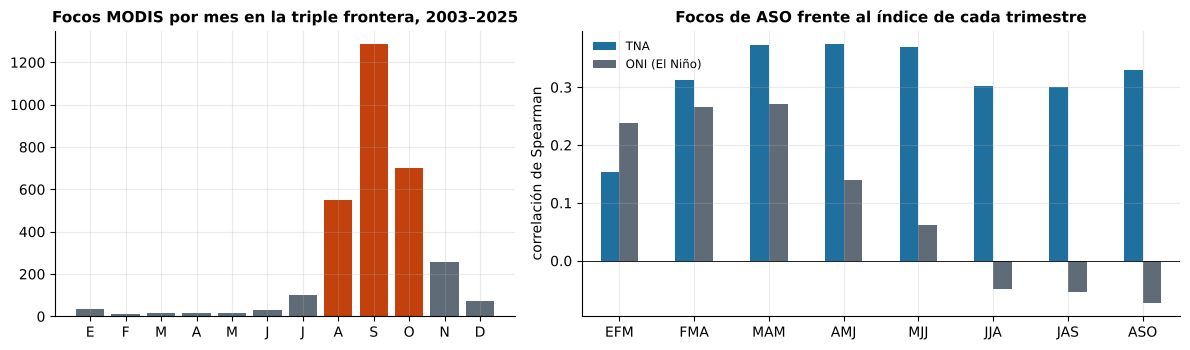

In [5]:
from leticia import pronostico
from leticia.config import aoi_cfg
from scipy import stats
reg = fuentes.focos_calor("modis", clave_bbox="bbox_fuego", paises=aoi_cfg()["paises_fuego"])
reg = reg[(reg["confidence"] >= pi["confianza_modis_min"]) & (reg["type"] == 0)]
anios = range(pi["anio_inicio_modis"], int(reg.index.year.max()) + 1)
mensual = reg[reg.index.year >= pi["anio_inicio_modis"]].groupby(reg.index.month[reg.index.year >= pi["anio_inicio_modis"]]).size().reindex(range(1, 13), fill_value=0)
temp = reg[reg.index.month.isin(pi["meses_temporada"])]
y = temp.groupby(temp.index.year).size().reindex(anios, fill_value=0)
tna, oni = fuentes.indice_tna(), fuentes.oni()
nombres = "EFMAMJJASOND"
ventanas = [[m, m + 1, m + 2] for m in range(1, 9)]
corr = pd.DataFrame({"TNA": [stats.spearmanr(pronostico.media_meses(tna, v).reindex(y.index), y)[0] for v in ventanas],
                     "ONI (El Niño)": [stats.spearmanr(pronostico.media_meses(oni, v).reindex(y.index), y)[0] for v in ventanas]},
                    index=["".join(nombres[m - 1] for m in v) for v in ventanas])
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6), gridspec_kw={"width_ratios": [1, 1.3]})
ax[0].bar(mensual.index, mensual, color=[viz.CALOR if m in pi["meses_temporada"] else viz.GRIS for m in mensual.index])
ax[0].set_xticks(range(1, 13)); ax[0].set_xticklabels(list(nombres))
ax[0].set_title(f"Focos MODIS por mes en la triple frontera, {anios[0]}–{anios[-1]}")
corr.plot.bar(ax=ax[1], color=[viz.AZUL_RIO, viz.GRIS], rot=0)
ax[1].axhline(0, color="k", lw=0.6)
ax[1].set_ylabel("correlación de Spearman")
ax[1].set_title("Focos de " + "".join(nombres[m - 1] for m in pi["meses_temporada"]) + " frente al índice de cada trimestre")
fig.tight_layout()
display(Markdown(f"Focos MODIS en la triple frontera ({anios[0]}–{anios[-1]}): **{len(reg[reg.index.year >= anios[0]]):,}**; ".replace(",", ".")
                 + f"el {100 * mensual.loc[pi['meses_temporada']].sum() / mensual.sum():.0f} % ocurre en agosto–octubre."))

In [6]:
viz.pie(viz.nota_fuente("focos_calor", "indice_tna", "indices_oceanicos") + " Extensión: 71,5–68,5° O y 5,5–2,5° S (Colombia, Perú y Brasil).")

*Fuente: NASA FIRMS — Archivo anual por país, MODIS (1 km, 2001–) y VIIRS S-NPP (375 m, 2012–); NOAA Physical Sciences Laboratory — TNA mensual (HadISST1.1, climatología 1991–2020), 1948–presente; NOAA Climate Prediction Center — ONI (ERSSTv5), trimestres móviles 1950–presente. Extensión: 71,5–68,5° O y 5,5–2,5° S (Colombia, Perú y Brasil).*

Modelo: log(focos) = 4.52 + 0.47 × TNA. Cada 1 °C de anomalía del TNA en marzo–mayo multiplica los focos de agosto–octubre por **1.6**. Validación cruzada dejando un año fuera (23 años): correlación **0.25** y habilidad frente a la climatología **0.12** (0 = no mejora el promedio, 1 = perfecto). Con el TNA de marzo–mayo de 2026 (+0.08 °C), el modelo estima para esa temporada **≈ 96 focos** (intervalo de 90 %: 62–183; mediana 2003–2025: 99); el archivo de FIRMS aún no publica ese año completo.

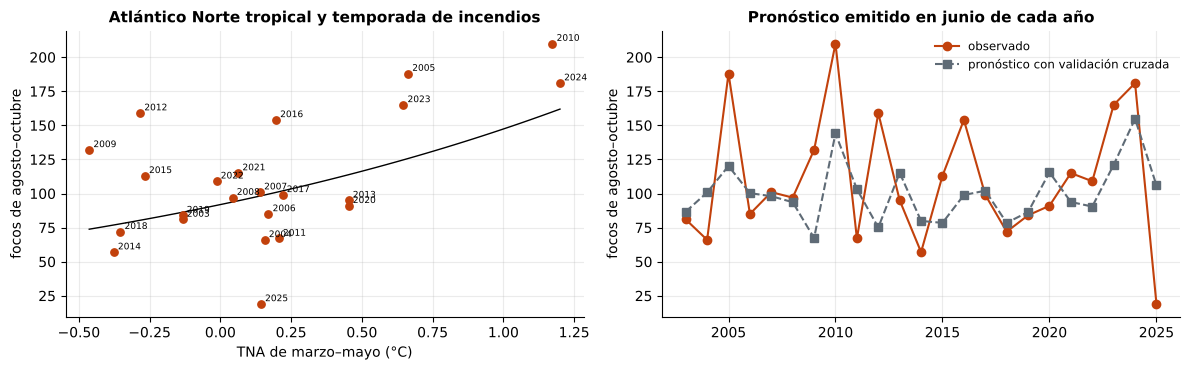

In [7]:
x = pronostico.media_meses(tna, pi["meses_predictor"])
X = x.reindex(y.index).to_frame("TNA")
ly = np.log(y.clip(lower=1))
ref, _ = pronostico.regresion_validada(ly, X.iloc[:, :0])
pred, coef = pronostico.regresion_validada(ly, X)
h = pronostico.habilidad(ly, pred, ref)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].scatter(X["TNA"], y, color=viz.CALOR, s=28, zorder=3)
for a, r_ in X.join(y.rename("focos")).iterrows():
    ax[0].annotate(str(a), (r_["TNA"], r_["focos"]), fontsize=6.5, xytext=(3, 2), textcoords="offset points")
xx = np.linspace(X["TNA"].min(), X["TNA"].max(), 50)
ax[0].plot(xx, np.exp(coef[0] + coef[1] * xx), color="k", lw=1)
ax[0].set_xlabel("TNA de marzo–mayo (°C)")
ax[0].set_ylabel("focos de agosto–octubre")
ax[0].set_title("Atlántico Norte tropical y temporada de incendios")
ax[1].plot(y.index, y, "o-", color=viz.CALOR, label="observado")
ax[1].plot(pred.index, np.exp(pred), "s--", color=viz.GRIS, label="pronóstico con validación cruzada")
ax[1].set_ylabel("focos de agosto–octubre")
ax[1].set_title("Pronóstico emitido en junio de cada año")
ax[1].legend()
fig.tight_layout()
texto = (f"Modelo: log(focos) = {coef[0]:.2f} + {coef[1]:.2f} × TNA. Cada 1 °C de anomalía del TNA en marzo–mayo multiplica los focos "
         f"de agosto–octubre por **{np.exp(coef[1]):.1f}**. Validación cruzada dejando un año fuera ({h['n']} años): correlación "
         f"**{h['r']:.2f}** y habilidad frente a la climatología **{h['habilidad']:.2f}** (0 = no mejora el promedio, 1 = perfecto).")
nuevo = [a for a in x.index if a > y.index.max()]
if nuevo:
    a = max(nuevo)
    c_, b_, s_ = pronostico.prediccion_con_intervalo(coef, [x.loc[a]], ly - pred)
    texto += (f" Con el TNA de marzo–mayo de {a} ({x.loc[a]:+.2f} °C), el modelo estima para esa temporada **≈ {np.exp(c_):.0f} focos** "
              f"(intervalo de 90 %: {np.exp(b_):.0f}–{np.exp(s_):.0f}; mediana {anios[0]}–{anios[-1]}: {y.median():.0f}); el archivo de FIRMS aún no "
              "publica ese año completo.")
display(Markdown(texto))

**Lectura.** El Atlántico Norte tropical sí deja una huella en la temporada de incendios de la triple frontera: los
años con más focos (2005, 2010 y 2024) tuvieron un TNA cálido en marzo–mayo, y la correlación con El Niño es menor.
En 2025, con un TNA cercano a lo normal, el número de focos detectados fue el más bajo de la serie. Pero la
habilidad del pronóstico es **modesta**: el índice explica una parte pequeña de la variación entre años, porque el
número de focos depende también de la deforestación, de las quemas agrícolas y de las nubes durante el paso del
satélite. En una extensión pequeña y con pocos focos, la señal climática pesa menos que la ignición humana: la TSM
indica el **riesgo de una temporada seca**, no cuántos incendios habrá. Un TNA muy cálido en primavera es razón suficiente
para preparar desde junio las campañas de prevención de quemas y los planes de contingencia por humo; la
validación año a año muestra cuánto pesar esa señal.

## 3. Escenarios de uso del suelo alrededor de la ciudad

In [8]:
loss = fuentes.bosque_hansen("lossyear")
tc = fuentes.bosque_hansen("treecover2000")
b = urbana.to_crs(4326).buffer(0.05).intersection(mun.geometry.iloc[0])   # ~5 km alrededor del área urbana, lado colombiano
l = loss.rio.write_crs(4326).rio.clip(b.geometry, drop=True)
t = tc.rio.write_crs(4326).rio.clip(b.geometry, drop=True)
px_ha = (0.00025 * 111320) ** 2 * np.cos(np.radians(4.2)) / 1e4
bosque2000 = float(((t.values >= 50) & np.isfinite(t.values)).sum()) * px_ha
perdida = pd.Series(l.values.ravel()).value_counts().drop(0, errors="ignore").sort_index() * px_ha
perdida.index = perdida.index.astype(int) + 2000
tasa = perdida.loc[2015:].mean()
restante = bosque2000 - perdida.sum()
filas = [{"escenario": "Tendencia 2015–2024", "pérdida anual (ha)": tasa, "bosque en 2050 (ha)": restante - tasa * 26},
         {"escenario": "Duplicación de la tasa", "pérdida anual (ha)": 2 * tasa, "bosque en 2050 (ha)": restante - 2 * tasa * 26},
         {"escenario": "Deforestación cero desde 2030 (Pacto de Leticia)", "pérdida anual (ha)": tasa,
          "bosque en 2050 (ha)": restante - tasa * 6}]
display(Markdown(f"Bosque (cobertura ≥ 50 %) en 2000 en un radio de ~5 km de la ciudad (lado colombiano): **{bosque2000:,.0f} ha**; perdido 2001–2024: "
                 f"{perdida.sum():,.0f} ha.".replace(",", ".")))
display(pd.DataFrame(filas).set_index("escenario").round(0))

Bosque (cobertura ≥ 50 %) en 2000 en un radio de ~5 km de la ciudad (lado colombiano): **8.443 ha**; perdido 2001–2024: 1.494 ha.

,pérdida anual (ha),bosque en 2050 (ha)
escenario,,
Tendencia 2015–2024,75.00,"5,001.00"
Duplicación de la tasa,150.00,"3,053.00"
Deforestación cero desde 2030 (Pacto de Leticia),75.00,"6,499.00"


**Lectura.** Los escenarios de uso del suelo son simples extrapolaciones de la tasa reciente de pérdida de bosque.
Su mensaje es de política: el **Pacto de Leticia por la Amazonía** (2019) y la Declaración de Belém (2023)
comprometen a los países amazónicos con la reducción de la deforestación. Para Leticia, conservar el bosque
periurbano reduce a la vez el riesgo de incendio, el calor urbano ([3.4](../34_calor/index.md)) y la presión sobre
las fuentes de agua.